# Fashion-MNIST Image Classification with PyTorch CNN

<div align="center">

**GPU-aware • Reproducible • Experiment-ready • Visual-first**

A complete deep-learning workflow for classifying 28 × 28 grayscale clothing images into ten categories. This notebook covers data validation, exploratory analysis, model design, mixed-precision training, evaluation, error analysis, interpretability, and clean artifact export.

</div>

---

### Project outputs

- **`images/`** — publication-ready exploratory plots, training curves, confusion matrices, feature maps, and prediction visualizations.
- **`artifacts/`** — model checkpoints, metrics, prediction tables, reports, experiment metadata, and run history.

The notebook is intentionally created without pre-filled execution outputs. Run the cells from top to bottom to generate fresh results. It locates the two CSV files beside the notebook or in common `data/`, `datasets/`, and Colab locations. It does not print filesystem paths in output cells.

## 1. Environment, reproducibility, and project setup

In [1]:
# 01 — Core imports
import json
import math
import os
import random
import time
import platform
import warnings
from copy import deepcopy
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from IPython.display import display

In [2]:
# 02 — Class names and visual identity
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
CLASS_COLORS = sns.color_palette("husl", n_colors=len(CLASS_NAMES))
ACCENT = "#5B5FEF"
DARK = "#20243A"
PALETTE = sns.color_palette("viridis", as_cmap=False)

In [3]:
# 03 — Reproducibility controls
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [4]:
# 04 — Create clean project output directories
PROJECT_DIR = Path.cwd()
IMAGES_DIR = PROJECT_DIR / "images"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = ARTIFACTS_DIR / "best_model_state.pt"

In [5]:
# 05 — Consistent chart styling and export helper
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({
    "figure.figsize": (10, 6), "figure.dpi": 110, "savefig.dpi": 240,
    "axes.titleweight": "bold", "axes.titlesize": 14,
    "axes.labelsize": 11, "grid.alpha": 0.22,
    "axes.spines.top": False, "axes.spines.right": False
})

def save_and_show(fig, filename):
    """Save a figure in images/ and display it without exposing its path."""
    fig.savefig(IMAGES_DIR / filename, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

In [6]:
# 06 — Select the best available compute device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"
if USE_CUDA:
    print("Compute device: CUDA GPU")
    print("GPU model:", torch.cuda.get_device_name(0))
else:
    print("Compute device: CPU (the notebook remains fully runnable)")

Compute device: CPU (the notebook remains fully runnable)


In [7]:
# 07 — Runtime and training configuration
BATCH_SIZE = 128
MAX_EPOCHS = 18
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
VALIDATION_SIZE = 0.10
EARLY_STOPPING_PATIENCE = 4
NUM_WORKERS = 0  # portable across local notebooks, Windows, and Colab
PIN_MEMORY = USE_CUDA
USE_AMP = USE_CUDA  # mixed precision is enabled only on CUDA

In [8]:
# 08 — Find the supplied CSVs without hard-coding a machine-specific location
def find_dataset_file(filename):
    candidates = [
        Path.cwd(), Path.cwd() / "data", Path.cwd() / "datasets",
        Path.cwd().parent, Path("/content"), Path("/content/data")
    ]
    for folder in candidates:
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"Could not locate {filename}. Place both Fashion-MNIST CSV files beside this notebook or inside data/."
    )

In [9]:
# 09 — Resolve and validate both dataset files
TRAIN_CSV = find_dataset_file("fashion-mnist_train.csv")
TEST_CSV = find_dataset_file("fashion-mnist_test.csv")
assert TRAIN_CSV.is_file() and TEST_CSV.is_file()
print("Both Fashion-MNIST CSV files were located successfully.")

Both Fashion-MNIST CSV files were located successfully.


In [10]:
# 10 — Load compactly: labels and pixel intensities fit in unsigned 8-bit integers
train_df = pd.read_csv(TRAIN_CSV, dtype=np.uint8)
test_df = pd.read_csv(TEST_CSV, dtype=np.uint8)
print("Training rows:", f"{len(train_df):,}", "| Test rows:", f"{len(test_df):,}")

Training rows: 60,000 | Test rows: 10,000


## 2. Data validation and exploratory analysis

In [11]:
# 11 — High-level dataset dimensions
dataset_overview = pd.DataFrame({
    "Split": ["Training", "Test"],
    "Rows": [len(train_df), len(test_df)],
    "Columns": [train_df.shape[1], test_df.shape[1]],
    "Image height": [28, 28],
    "Image width": [28, 28]
})
display(dataset_overview)

,Split,Rows,Columns,Image height,Image width
0,Training,60000,785,28,28
1,Test,10000,785,28,28


In [12]:
# 12 — Inspect a small, readable sample
display(train_df.head(5).iloc[:, :12])

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,pixel11
0,2,0,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,0,0
3,0,0,0,0,1,2,0,0,0,0,0,114
4,3,0,0,0,0,0,0,0,0,0,0,0


In [13]:
# 13 — Confirm label and pixel column structure
expected_pixel_columns = [f"pixel{i}" for i in range(1, 785)]
assert "label" in train_df.columns and "label" in test_df.columns
assert [c for c in train_df.columns if c != "label"] == expected_pixel_columns
assert [c for c in test_df.columns if c != "label"] == expected_pixel_columns
assert train_df["label"].between(0, 9).all() and test_df["label"].between(0, 9).all()
print("Schema checks passed: one label column and 784 pixel columns per image.")

Schema checks passed: one label column and 784 pixel columns per image.


In [14]:
# 14 — Missing-value audit
missing_summary = pd.DataFrame({
    "Training missing": train_df.isna().sum(),
    "Test missing": test_df.isna().sum()
})
print("Total missing values:", int(missing_summary.to_numpy().sum()))
display(missing_summary.sum().to_frame("Missing values"))

Total missing values: 0


,Missing values
Training missing,0
Test missing,0


In [15]:
# 15 — Data type audit
dtype_summary = pd.concat([
    train_df.dtypes.value_counts().rename("Training"),
    test_df.dtypes.value_counts().rename("Test")
], axis=1).fillna(0).astype(int)
display(dtype_summary)

,Training,Test
uint8,785,785


In [16]:
# 16 — Validate pixel intensity boundaries
train_pixel_values = train_df[expected_pixel_columns].to_numpy()
test_pixel_values = test_df[expected_pixel_columns].to_numpy()
pixel_min = int(min(train_pixel_values.min(), test_pixel_values.min()))
pixel_max = int(max(train_pixel_values.max(), test_pixel_values.max()))
assert pixel_min >= 0 and pixel_max <= 255
print(f"Observed pixel range: {pixel_min} to {pixel_max}")

Observed pixel range: 0 to 255


In [17]:
# 17 — Label counts for both supplied splits
train_label_counts = train_df["label"].value_counts().sort_index()
test_label_counts = test_df["label"].value_counts().sort_index()
label_counts = pd.DataFrame({"Training": train_label_counts, "Test": test_label_counts})
label_counts.index = CLASS_NAMES
display(label_counts)

,Training,Test
T-shirt/top,6000,1000
Trouser,6000,1000
Pullover,6000,1000
Dress,6000,1000
Coat,6000,1000
Sandal,6000,1000
Shirt,6000,1000
Sneaker,6000,1000
Bag,6000,1000
Ankle boot,6000,1000


In [18]:
# 18 — Duplicate-row audit
duplicate_summary = pd.Series({
    "Training duplicate rows": int(train_df.duplicated().sum()),
    "Test duplicate rows": int(test_df.duplicated().sum())
}, name="Count")
display(duplicate_summary.to_frame())

,Count
Training duplicate rows,43
Test duplicate rows,1


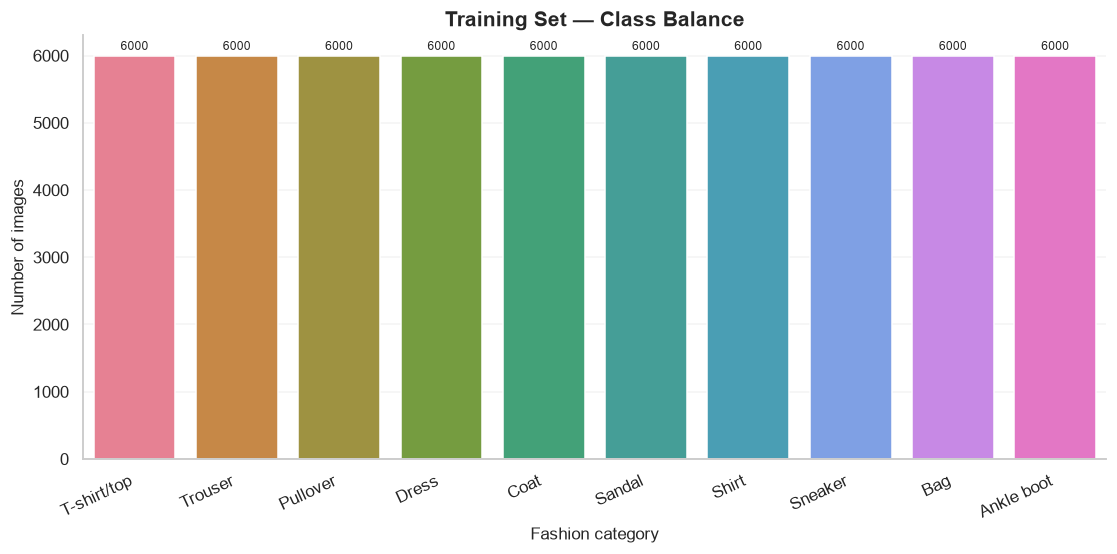

In [19]:
# 19 — Training label distribution
fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(data=train_df, x="label", hue="label", palette=CLASS_COLORS, legend=False, ax=ax)
ax.set(title="Training Set — Class Balance", xlabel="Fashion category", ylabel="Number of images")
ax.set_xticks(range(10), CLASS_NAMES, rotation=25, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=2, fontsize=8)
save_and_show(fig, "01_training_class_distribution.png")

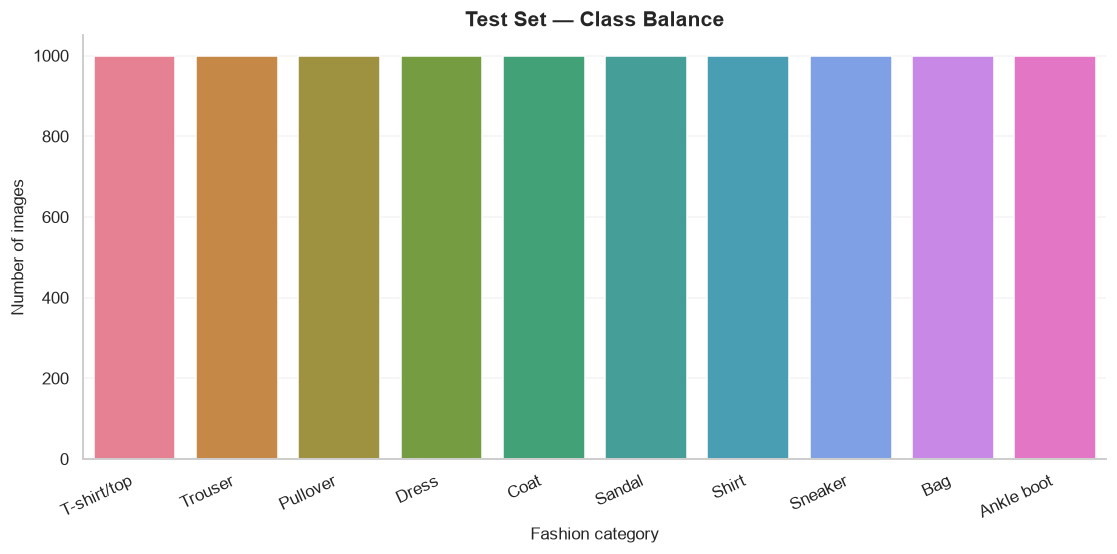

In [20]:
# 20 — Test label distribution
fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(data=test_df, x="label", hue="label", palette=CLASS_COLORS, legend=False, ax=ax)
ax.set(title="Test Set — Class Balance", xlabel="Fashion category", ylabel="Number of images")
ax.set_xticks(range(10), CLASS_NAMES, rotation=25, ha="right")
save_and_show(fig, "02_test_class_distribution.png")

In [21]:
# 21 — Reusable image-grid visualizer
def show_image_grid(images, labels=None, predictions=None, confidences=None,
                    nrows=4, ncols=5, title="Fashion-MNIST samples", filename=None):
    total = min(len(images), nrows * ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.1, nrows * 2.35))
    axes = np.array(axes).reshape(-1)
    for idx, ax in enumerate(axes):
        ax.axis("off")
        if idx >= total:
            continue
        ax.imshow(np.asarray(images[idx]).reshape(28, 28), cmap="mako", vmin=0, vmax=255)
        if labels is not None:
            caption = CLASS_NAMES[int(labels[idx])]
            if predictions is not None:
                caption += f"\nPred: {CLASS_NAMES[int(predictions[idx])]}"
            if confidences is not None:
                caption += f" ({float(confidences[idx]):.0%})"
            ax.set_title(caption, fontsize=8, color=DARK)
    fig.suptitle(title, fontsize=16, fontweight="bold", y=1.01)
    fig.tight_layout()
    if filename:
        save_and_show(fig, filename)
    else:
        plt.show()
        plt.close(fig)

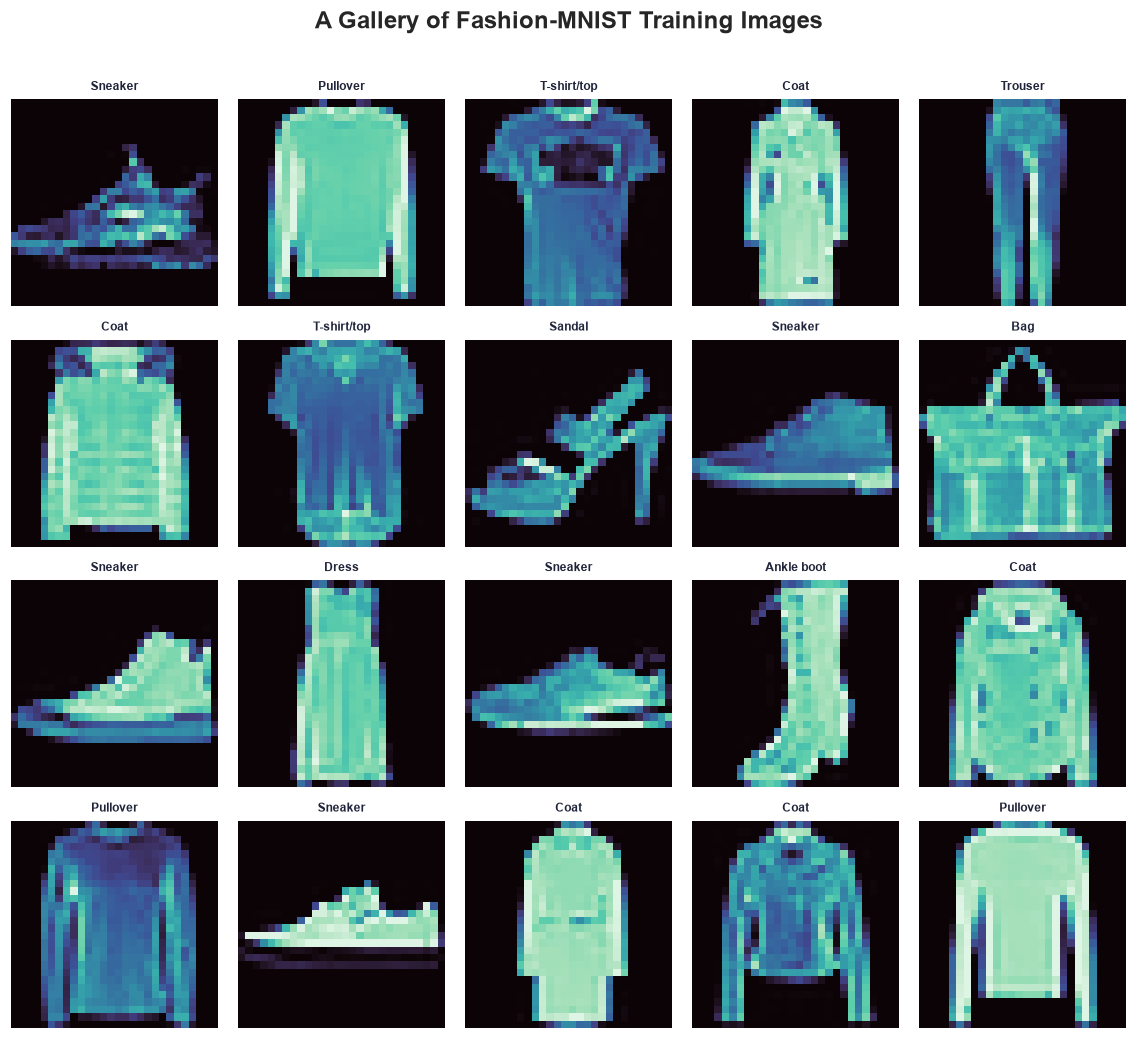

In [22]:
# 22 — View a random sample of training images
rng = np.random.default_rng(SEED)
random_indices = rng.choice(len(train_df), size=20, replace=False)
show_image_grid(
    train_pixel_values[random_indices], train_df["label"].to_numpy()[random_indices],
    title="A Gallery of Fashion-MNIST Training Images",
    filename="03_random_training_gallery.png"
)

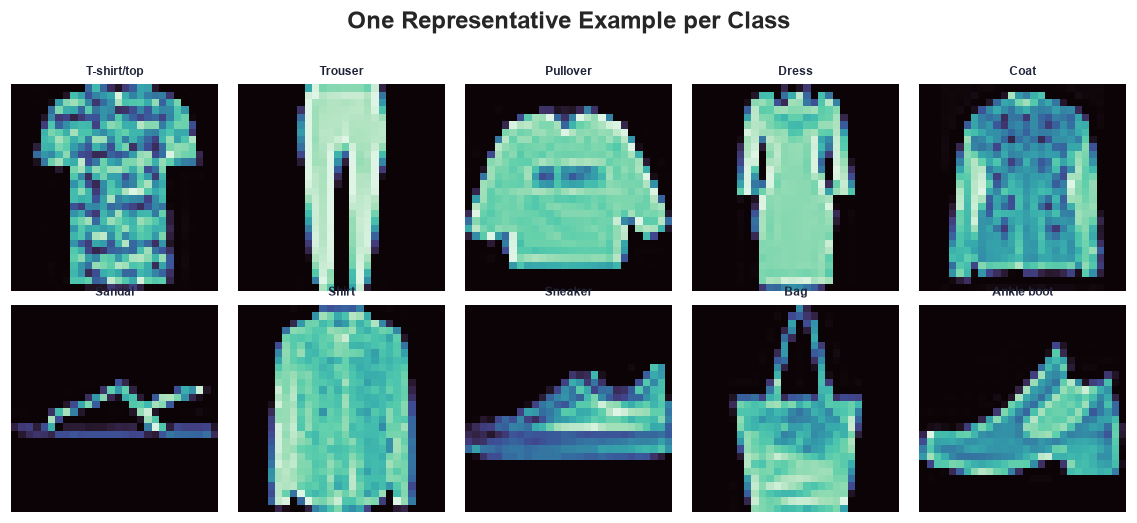

In [23]:
# 23 — One representative image from every class
representative_indices = [int(np.flatnonzero(train_df["label"].to_numpy() == cls)[0]) for cls in range(10)]
show_image_grid(
    train_pixel_values[representative_indices], np.arange(10), nrows=2, ncols=5,
    title="One Representative Example per Class",
    filename="04_one_example_per_class.png"
)

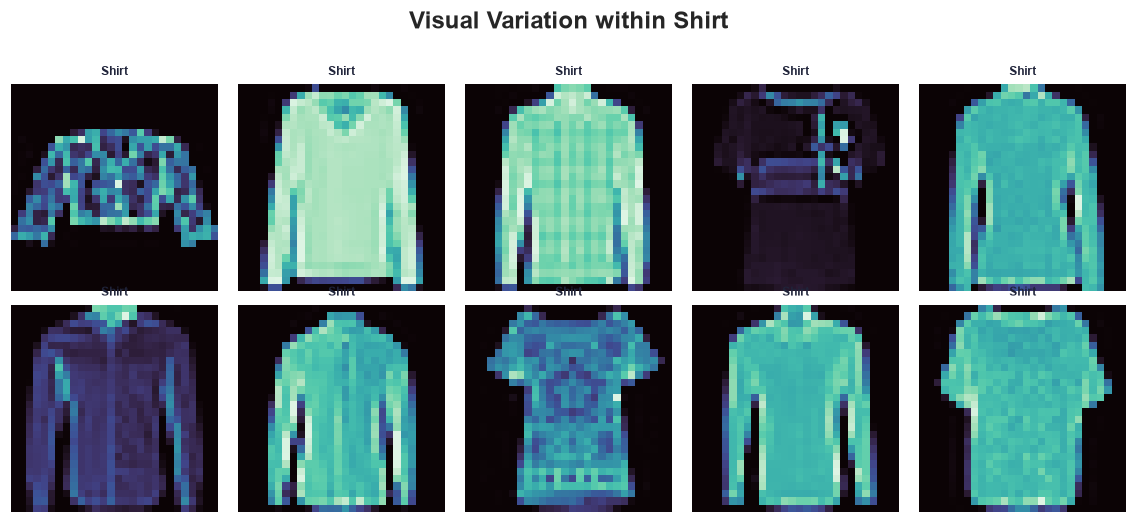

In [24]:
# 24 — Random examples from a selected class
selected_class = 6  # Shirt
selected_indices = np.flatnonzero(train_df["label"].to_numpy() == selected_class)
selected_indices = rng.choice(selected_indices, size=10, replace=False)
show_image_grid(
    train_pixel_values[selected_indices], train_df["label"].to_numpy()[selected_indices],
    nrows=2, ncols=5, title=f"Visual Variation within {CLASS_NAMES[selected_class]}",
    filename="05_within_class_variation.png"
)

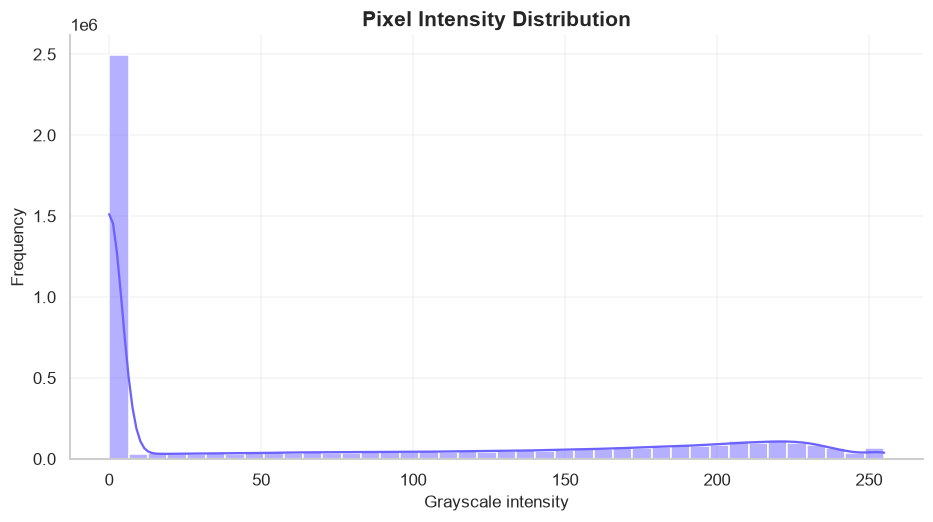

In [25]:
# 25 — Pixel intensity distribution
pixel_sample = train_pixel_values[::10].ravel()
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(pixel_sample, bins=40, kde=True, color="#6C63FF", ax=ax)
ax.set(title="Pixel Intensity Distribution", xlabel="Grayscale intensity", ylabel="Frequency")
save_and_show(fig, "06_pixel_intensity_distribution.png")

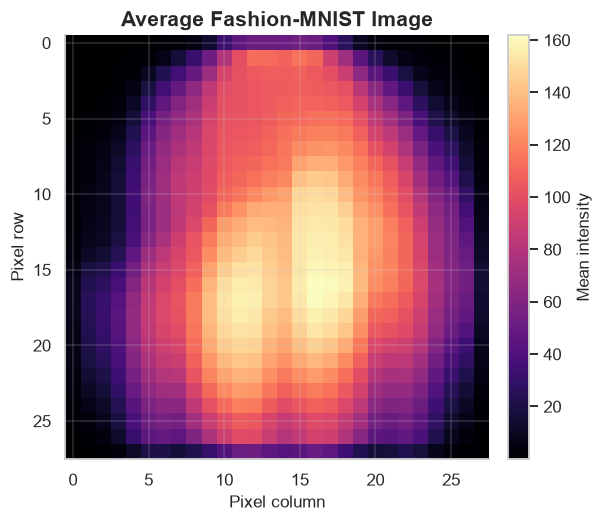

In [26]:
# 26 — Average image across the training set
mean_image = train_pixel_values.mean(axis=0).reshape(28, 28)
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(mean_image, cmap="magma")
ax.set(title="Average Fashion-MNIST Image", xlabel="Pixel column", ylabel="Pixel row")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Mean intensity")
save_and_show(fig, "07_global_mean_image.png")

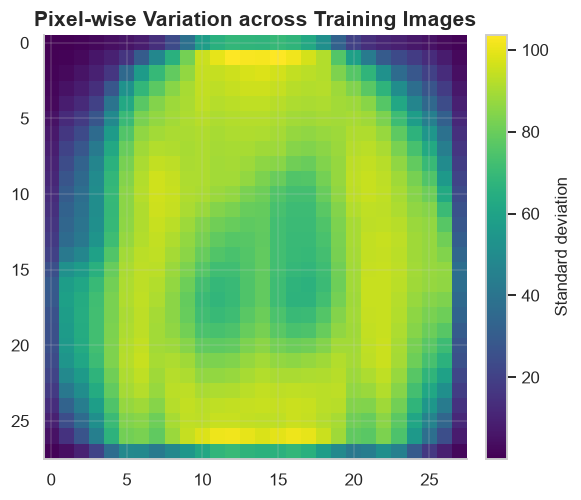

In [27]:
# 27 — Pixel-wise standard deviation
std_image = train_pixel_values.astype(np.float32).std(axis=0).reshape(28, 28)
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(std_image, cmap="viridis")
ax.set(title="Pixel-wise Variation across Training Images")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Standard deviation")
save_and_show(fig, "08_pixel_variability.png")

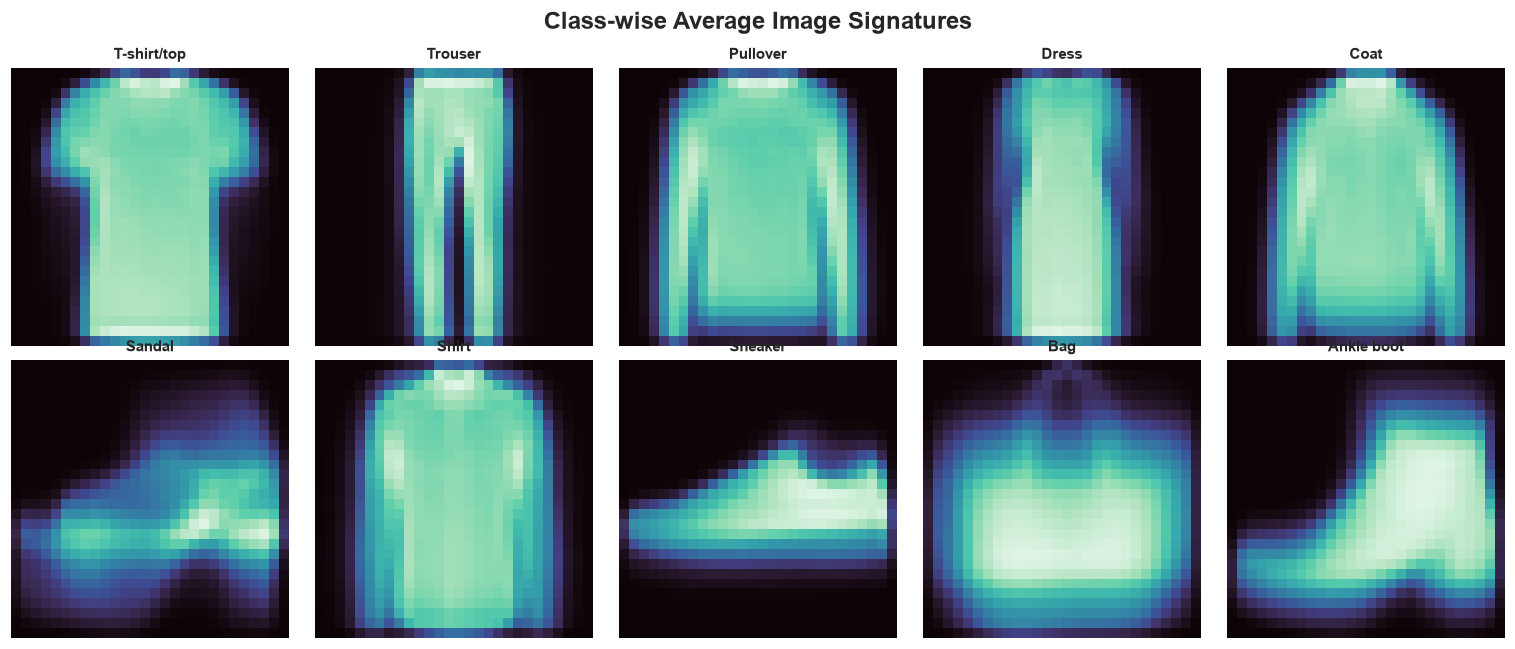

In [28]:
# 28 — Mean image for every fashion category
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for cls, ax in enumerate(axes.flat):
    class_pixels = train_pixel_values[train_df["label"].to_numpy() == cls]
    ax.imshow(class_pixels.mean(axis=0).reshape(28, 28), cmap="mako")
    ax.set_title(CLASS_NAMES[cls], fontsize=10, fontweight="bold")
    ax.axis("off")
fig.suptitle("Class-wise Average Image Signatures", fontsize=16, fontweight="bold")
fig.tight_layout()
save_and_show(fig, "09_class_mean_images.png")

In [29]:
# 29 — Per-class intensity summary
class_intensity = train_df.groupby("label")[expected_pixel_columns].mean().mean(axis=1)
class_intensity.index = CLASS_NAMES
class_intensity = class_intensity.sort_values(ascending=False)
display(class_intensity.rename("Average pixel intensity").to_frame())

,Average pixel intensity
Coat,98.155656
Pullover,95.719328
Bag,90.035762
Shirt,85.115098
T-shirt/top,82.879264
Ankle boot,77.007150
Dress,66.201487
Trouser,56.748372
Sneaker,42.835672
Sandal,34.870517


## 3. Leakage-safe preparation and PyTorch data pipeline

In [30]:
# 30 — Create a stratified validation split from training data only
all_train_labels = train_df["label"].to_numpy(dtype=np.int64)
train_indices, val_indices = train_test_split(
    np.arange(len(train_df)), test_size=VALIDATION_SIZE,
    random_state=SEED, stratify=all_train_labels
)
print(f"Training subset: {len(train_indices):,} | Validation subset: {len(val_indices):,}")

Training subset: 54,000 | Validation subset: 6,000


In [31]:
# 31 — Separate images and labels
X_all = train_df[expected_pixel_columns].to_numpy(dtype=np.uint8)
y_all = all_train_labels
X_train_raw, X_val_raw = X_all[train_indices], X_all[val_indices]
y_train, y_val = y_all[train_indices], y_all[val_indices]
X_test_raw = test_df[expected_pixel_columns].to_numpy(dtype=np.uint8)
y_test = test_df["label"].to_numpy(dtype=np.int64)

In [32]:
# 32 — Normalize pixels and reshape to N × 1 × 28 × 28
def prepare_images(pixel_array):
    return (pixel_array.reshape(-1, 1, 28, 28).astype(np.float32) / 255.0)
X_train = prepare_images(X_train_raw)
X_val = prepare_images(X_val_raw)
X_test = prepare_images(X_test_raw)
print("Image tensors are normalized to [0, 1].")

Image tensors are normalized to [0, 1].


In [33]:
# 33 — Verify split sizes, shapes, and label coverage
split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Images": [len(X_train), len(X_val), len(X_test)],
    "Tensor shape": [str(X_train.shape[1:]), str(X_val.shape[1:]), str(X_test.shape[1:])],
    "Unique labels": [len(np.unique(y_train)), len(np.unique(y_val)), len(np.unique(y_test))]
})
display(split_summary)
assert X_train.shape[1:] == (1, 28, 28) and len(np.unique(y_test)) == 10

,Split,Images,Tensor shape,Unique labels
0,Train,54000,"(1, 28, 28)",10
1,Validation,6000,"(1, 28, 28)",10
2,Test,10000,"(1, 28, 28)",10


In [34]:
# 34 — Custom Dataset class
class FashionDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(np.ascontiguousarray(images, dtype=np.float32))
        self.labels = torch.from_numpy(np.ascontiguousarray(labels, dtype=np.int64))
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return self.images[index], self.labels[index]

In [35]:
# 35 — Build Dataset objects
train_dataset = FashionDataset(X_train, y_train)
val_dataset = FashionDataset(X_val, y_val)
test_dataset = FashionDataset(X_test, y_test)
print("Dataset objects initialized.")

Dataset objects initialized.


In [36]:
# 36 — Reproducible DataLoaders
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, generator=loader_generator
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)

In [37]:
# 37 — Inspect one data batch
batch_images, batch_labels = next(iter(train_loader))
print("Batch image shape:", tuple(batch_images.shape))
print("Batch label shape:", tuple(batch_labels.shape))
print("Batch tensor range:", float(batch_images.min()), "to", float(batch_images.max()))

Batch image shape: (128, 1, 28, 28)
Batch label shape: (128,)
Batch tensor range: 0.0 to 1.0


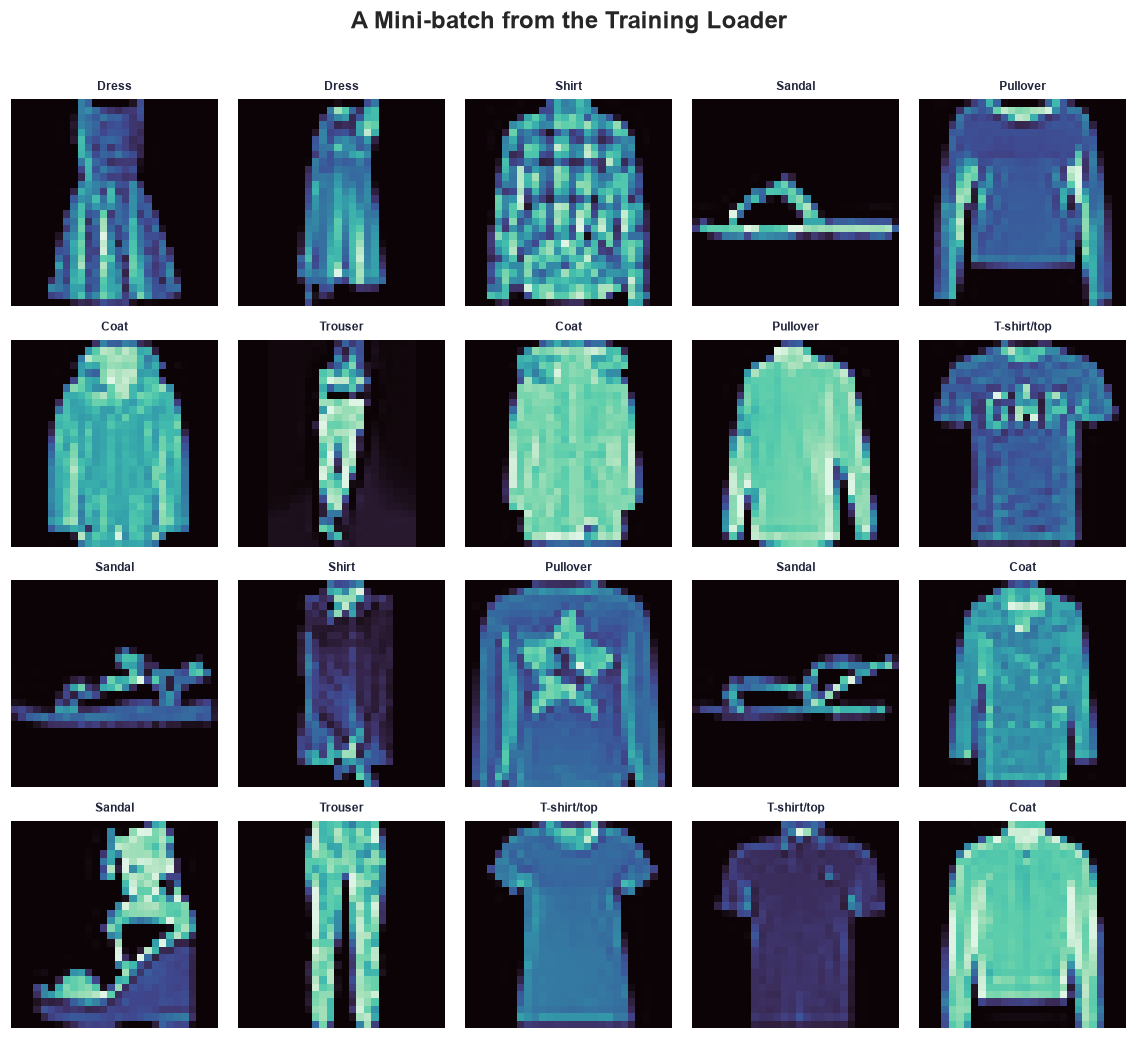

In [38]:
# 38 — Visualize a training batch
batch_display = (batch_images[:20].squeeze(1).numpy() * 255).clip(0, 255).astype(np.uint8)
show_image_grid(
    batch_display, batch_labels[:20].numpy(), nrows=4, ncols=5,
    title="A Mini-batch from the Training Loader",
    filename="10_training_batch_gallery.png"
)

In [39]:
# 39 — Batch-level numeric diagnostics
batch_summary = pd.Series({
    "Mean normalized intensity": float(batch_images.mean()),
    "Standard deviation": float(batch_images.std()),
    "Minimum": float(batch_images.min()),
    "Maximum": float(batch_images.max())
}, name="Value")
display(batch_summary.to_frame())

,Value
Mean normalized intensity,0.278078
Standard deviation,0.342946
Minimum,0.000000
Maximum,1.000000


In [40]:
# 40 — Class frequencies and optional balanced class weights
class_frequency = np.bincount(y_train, minlength=10)
class_weights_np = len(y_train) / (10.0 * np.maximum(class_frequency, 1))
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)
print("Training labels cover all ten categories.")

Training labels cover all ten categories.


## 4. CNN architecture and optimization setup

In [41]:
# 41 — Reusable convolution block
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dropout=0.05):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.activation = nn.GELU()
        self.pool = nn.MaxPool2d(2)
        self.dropout = nn.Dropout2d(dropout)
    def forward(self, x):
        x = self.activation(self.bn1(self.conv1(x)))
        x = self.activation(self.bn2(self.conv2(x)))
        return self.dropout(self.pool(x))

In [42]:
# 42 — FashionCNN model definition
class FashionCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.block1 = ConvBlock(1, 32, dropout=0.03)
        self.block2 = ConvBlock(32, 64, dropout=0.06)
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.GELU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128, 128), nn.GELU(),
            nn.Dropout(0.35), nn.Linear(128, num_classes)
        )
    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.classifier(x)

In [43]:
# 43 — Initialize the network
model = FashionCNN(num_classes=len(CLASS_NAMES)).to(DEVICE)
print("FashionCNN is ready on the selected compute device.")

FashionCNN is ready on the selected compute device.


In [44]:
# 44 — Parameter count by model component
parameter_rows = []
for name, module in model.named_children():
    count = sum(parameter.numel() for parameter in module.parameters() if parameter.requires_grad)
    parameter_rows.append({"Component": name, "Trainable parameters": count})
parameter_summary = pd.DataFrame(parameter_rows)
parameter_summary.loc[len(parameter_summary)] = {
    "Component": "TOTAL", "Trainable parameters": sum(p.numel() for p in model.parameters() if p.requires_grad)
}
display(parameter_summary)

,Component,Trainable parameters
0,block1,9632
1,block2,55552
2,block3,73984
3,classifier,17802
4,TOTAL,156970


In [45]:
# 45 — Forward-pass shape check
with torch.no_grad():
    sample_logits = model(batch_images[:4].to(DEVICE))
assert sample_logits.shape == (4, 10)
print("Forward-pass output shape:", tuple(sample_logits.shape))

Forward-pass output shape: (4, 10)


In [46]:
# 46 — Record architecture and experiment configuration
MODEL_CONFIG = {
    "architecture": "FashionCNN", "input_shape": [1, 28, 28],
    "num_classes": 10, "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS, "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY, "seed": SEED
}
display(pd.Series(MODEL_CONFIG, name="Configuration").to_frame())

,Configuration
architecture,FashionCNN
input_shape,"[1, 28, 28]"
num_classes,10
batch_size,128
max_epochs,18
learning_rate,0.001
weight_decay,0.0001
seed,42


In [47]:
# 47 — Loss function
criterion = nn.CrossEntropyLoss()

In [48]:
# 48 — AdamW optimizer
optimizer = optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)

In [49]:
# 49 — Learning-rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-6
)

In [50]:
# 50 — CUDA mixed-precision scaler
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
print("Automatic mixed precision:", "enabled" if USE_AMP else "disabled")

Automatic mixed precision: disabled


C:\Users\as178\AppData\Local\Temp\ipykernel_20984\2929259775.py:2: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


## 5. Training, validation, and checkpoint selection

In [51]:
# 51 — One complete training epoch
def train_one_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return {"loss": running_loss / total, "accuracy": correct / total}

In [52]:
# 52 — Validation/evaluation function
@torch.no_grad()
def evaluate_model(model, loader, criterion, collect=False):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    true_parts, pred_parts, probability_parts = [], [], []
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)
        logits = model(images)
        loss = criterion(logits, labels)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)
        running_loss += loss.item() * labels.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
        if collect:
            true_parts.append(labels.cpu().numpy())
            pred_parts.append(predictions.cpu().numpy())
            probability_parts.append(probabilities.cpu().numpy())
    result = {"loss": running_loss / total, "accuracy": correct / total}
    if collect:
        result.update({
            "y_true": np.concatenate(true_parts),
            "y_pred": np.concatenate(pred_parts),
            "probabilities": np.concatenate(probability_parts)
        })
    return result

In [53]:
# 53 — Early stopping with best-validation-loss checkpointing
class EarlyStopping:
    def __init__(self, patience=4, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.best_epoch = 0
    def step(self, validation_loss, epoch, model):
        improved = validation_loss < self.best_loss - self.min_delta
        if improved:
            self.best_loss = validation_loss
            self.best_epoch = epoch
            self.counter = 0
            torch.save(model.state_dict(), BEST_CHECKPOINT_PATH)
        else:
            self.counter += 1
        return self.counter >= self.patience

In [54]:
# 54 — Initialize training history
history = {
    "epoch": [], "train_loss": [], "val_loss": [],
    "train_accuracy": [], "val_accuracy": [], "learning_rate": []
}
early_stopper = EarlyStopping(patience=EARLY_STOPPING_PATIENCE)

In [55]:
# 55 — Training plan summary
print(f"Maximum epochs: {MAX_EPOCHS} | Early-stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"Batch size: {BATCH_SIZE} | Initial learning rate: {LEARNING_RATE:g}")
print("The validation split selects the checkpoint; the test split remains untouched until final evaluation.")

Maximum epochs: 18 | Early-stopping patience: 4
Batch size: 128 | Initial learning rate: 0.001
The validation split selects the checkpoint; the test split remains untouched until final evaluation.


In [56]:
# 56 — Train the CNN
training_start = time.perf_counter()
for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_metrics = train_one_epoch(model, train_loader, optimizer, criterion, scaler)
    val_metrics = evaluate_model(model, val_loader, criterion, collect=False)
    scheduler.step(val_metrics["loss"])
    current_lr = optimizer.param_groups[0]["lr"]
    history["epoch"].append(epoch)
    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["learning_rate"].append(current_lr)
    elapsed = time.perf_counter() - epoch_start
    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | val loss {val_metrics['loss']:.4f} | "
        f"train acc {train_metrics['accuracy']:.3%} | val acc {val_metrics['accuracy']:.3%} | "
        f"lr {current_lr:.2e} | {elapsed:.1f}s"
    )
    if early_stopper.step(val_metrics["loss"], epoch, model):
        print("Early stopping criterion reached.")
        break
training_duration = time.perf_counter() - training_start
print("Training run completed.")

Epoch 01/18 | train loss 0.6448 | val loss 0.4466 | train acc 76.593% | val acc 83.133% | lr 1.00e-03 | 74.5s
Epoch 02/18 | train loss 0.3628 | val loss 0.3017 | train acc 86.806% | val acc 89.000% | lr 1.00e-03 | 73.3s
Epoch 03/18 | train loss 0.3032 | val loss 0.2610 | train acc 88.911% | val acc 90.700% | lr 1.00e-03 | 72.9s
Epoch 04/18 | train loss 0.2678 | val loss 0.2399 | train acc 90.406% | val acc 91.350% | lr 1.00e-03 | 72.5s
Epoch 05/18 | train loss 0.2446 | val loss 0.2239 | train acc 91.224% | val acc 91.800% | lr 1.00e-03 | 74.1s
Epoch 06/18 | train loss 0.2281 | val loss 0.2364 | train acc 91.844% | val acc 91.950% | lr 1.00e-03 | 97.4s
Epoch 07/18 | train loss 0.2088 | val loss 0.2235 | train acc 92.507% | val acc 92.000% | lr 1.00e-03 | 71.7s
Epoch 08/18 | train loss 0.1958 | val loss 0.2066 | train acc 93.046% | val acc 92.750% | lr 1.00e-03 | 75.2s
Epoch 09/18 | train loss 0.1830 | val loss 0.1993 | train acc 93.400% | val acc 92.983% | lr 1.00e-03 | 77.1s
Epoch 10/1

In [57]:
# 57 — Convert training history to a DataFrame
history_df = pd.DataFrame(history)
display(history_df.tail())

,epoch,train_loss,val_loss,train_accuracy,val_accuracy,learning_rate
13,14,0.107267,0.191751,0.961556,0.931667,0.00050
14,15,0.096939,0.197565,0.965500,0.932500,0.00050
15,16,0.088976,0.224449,0.967852,0.927167,0.00050
16,17,0.082632,0.214011,0.969926,0.930333,0.00025
17,18,0.063712,0.224664,0.977463,0.932833,0.00025


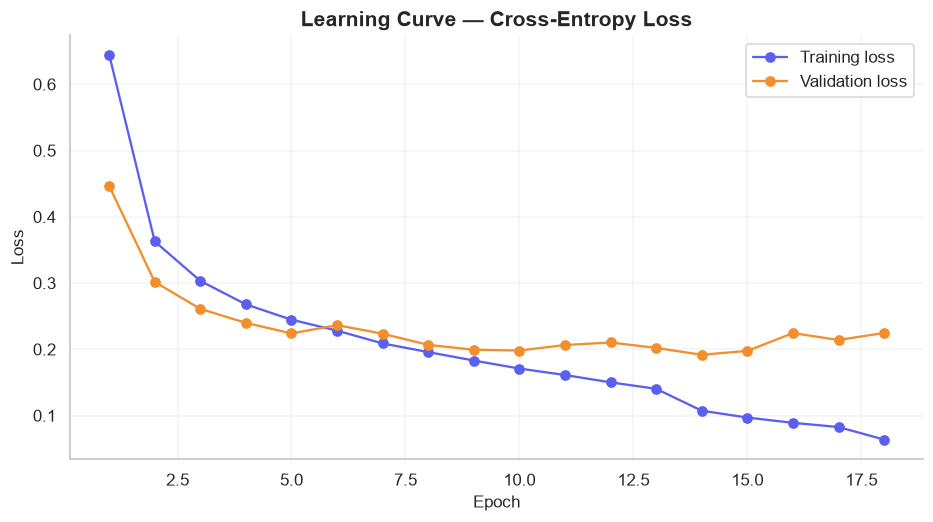

In [58]:
# 58 — Training and validation loss curves
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training loss", color="#5B5FEF")
ax.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss", color="#F28E2B")
ax.set(title="Learning Curve — Cross-Entropy Loss", xlabel="Epoch", ylabel="Loss")
ax.legend(frameon=True)
save_and_show(fig, "11_training_validation_loss.png")

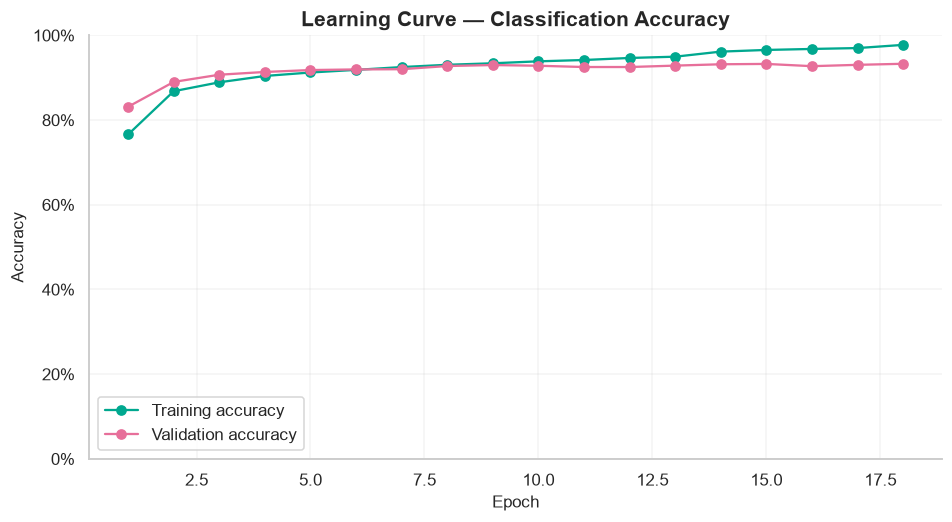

In [59]:
# 59 — Training and validation accuracy curves
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_accuracy"], marker="o", label="Training accuracy", color="#00A88F")
ax.plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation accuracy", color="#E76F9A")
ax.set(title="Learning Curve — Classification Accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.legend(frameon=True)
save_and_show(fig, "12_training_validation_accuracy.png")

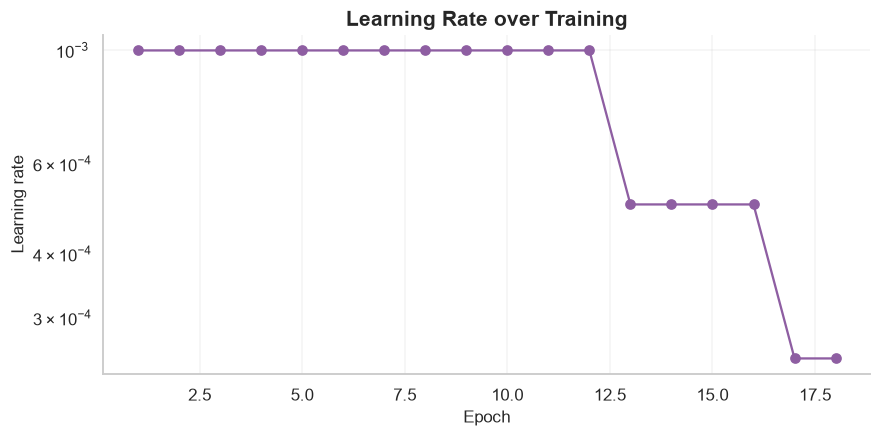

In [60]:
# 60 — Learning-rate schedule
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history_df["epoch"], history_df["learning_rate"], marker="o", color="#8E5EA2")
ax.set(title="Learning Rate over Training", xlabel="Epoch", ylabel="Learning rate")
ax.set_yscale("log")
save_and_show(fig, "13_learning_rate_schedule.png")

## 6. Final evaluation on the untouched test set

In [61]:
# 61 — Restore the checkpoint with the best validation loss
try:
    best_state = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
except TypeError:  # compatibility with older PyTorch releases
    best_state = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(best_state)
model.eval()
print(f"Best checkpoint selected at epoch {early_stopper.best_epoch}.")

Best checkpoint selected at epoch 14.


In [62]:
# 62 — Evaluate the training subset
train_final_metrics = evaluate_model(model, train_loader, criterion, collect=False)
print(f"Training accuracy: {train_final_metrics['accuracy']:.3%}")

Training accuracy: 97.698%


In [63]:
# 63 — Evaluate the validation subset
val_final_metrics = evaluate_model(model, val_loader, criterion, collect=False)
print(f"Validation accuracy: {val_final_metrics['accuracy']:.3%}")

Validation accuracy: 93.167%


In [64]:
# 64 — Evaluate the official test set and collect predictions
test_results = evaluate_model(model, test_loader, criterion, collect=True)
print(f"Test accuracy: {test_results['accuracy']:.3%}")
print(f"Test loss: {test_results['loss']:.4f}")

Test accuracy: 93.550%
Test loss: 0.1904


In [65]:
# 65 — Compact headline metrics
headline_metrics = {
    "train_accuracy": train_final_metrics["accuracy"],
    "validation_accuracy": val_final_metrics["accuracy"],
    "test_accuracy": test_results["accuracy"],
    "test_loss": test_results["loss"],
    "epochs_completed": len(history_df),
    "best_epoch": early_stopper.best_epoch,
    "training_minutes": training_duration / 60
}
display(pd.Series(headline_metrics, name="Result").to_frame())

,Result
train_accuracy,0.976981
validation_accuracy,0.931667
test_accuracy,0.935500
test_loss,0.190410
epochs_completed,18.000000
best_epoch,14.000000
training_minutes,23.082166


In [66]:
# 66 — Full classification report
report_dict = classification_report(
    test_results["y_true"], test_results["y_pred"],
    labels=np.arange(10), target_names=CLASS_NAMES,
    output_dict=True, zero_division=0
)
print(classification_report(
    test_results["y_true"], test_results["y_pred"],
    labels=np.arange(10), target_names=CLASS_NAMES, zero_division=0
))

              precision    recall  f1-score   support

 T-shirt/top       0.86      0.91      0.88      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.93      0.89      0.91      1000
       Dress       0.92      0.94      0.93      1000
        Coat       0.91      0.91      0.91      1000
      Sandal       0.99      0.98      0.99      1000
       Shirt       0.84      0.80      0.82      1000
     Sneaker       0.96      0.97      0.96      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.97      0.98      0.97      1000

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



In [67]:
# 67 — Class-wise precision, recall, and F1 table
report_df = pd.DataFrame(report_dict).T.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]]
display(report_df.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}", "support": "{:.0f}"})
      .background_gradient(cmap="YlGnBu", subset=["precision", "recall", "f1-score"]))

,precision,recall,f1-score,support
T-shirt/top,0.858,0.905,0.881,1000
Trouser,0.992,0.995,0.994,1000
Pullover,0.926,0.887,0.906,1000
Dress,0.924,0.943,0.933,1000
Coat,0.909,0.909,0.909,1000
Sandal,0.995,0.977,0.986,1000
Shirt,0.835,0.796,0.815,1000
Sneaker,0.957,0.972,0.964,1000
Bag,0.988,0.995,0.992,1000
Ankle boot,0.971,0.976,0.974,1000


In [68]:
# 68 — Confusion matrix values
cm = confusion_matrix(test_results["y_true"], test_results["y_pred"], labels=np.arange(10))
normalized_cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

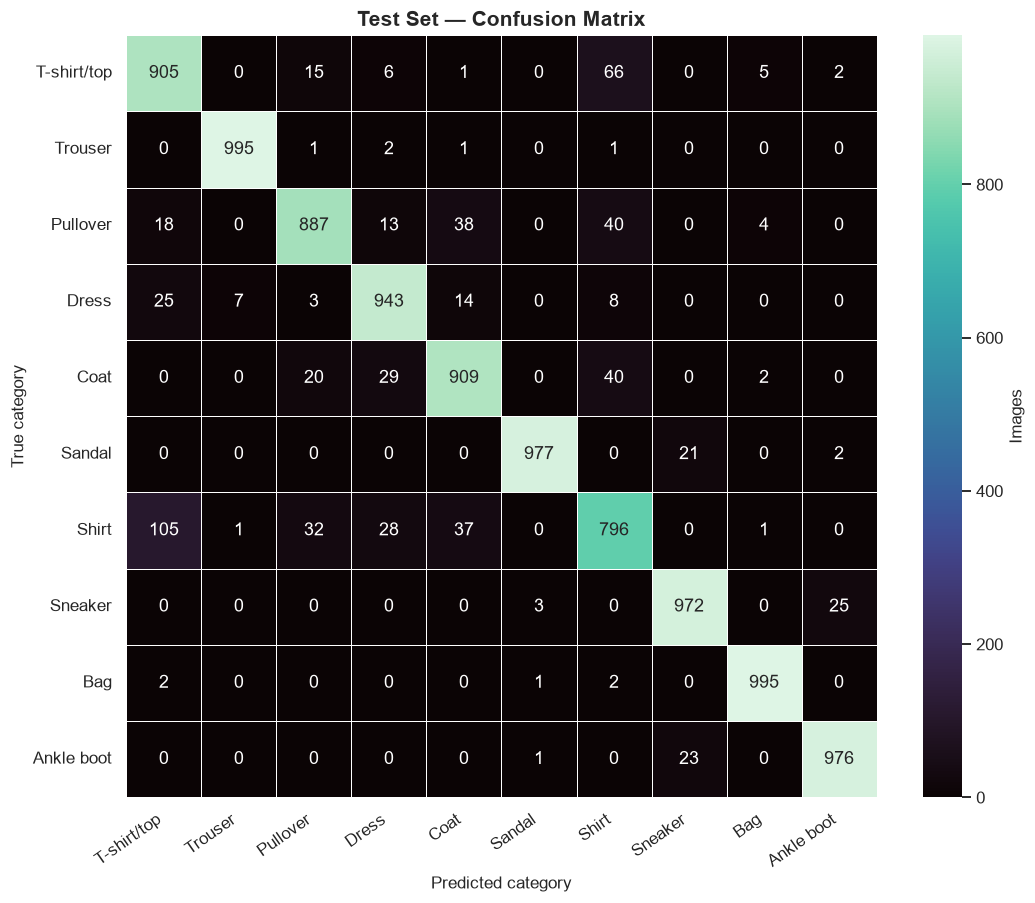

In [69]:
# 69 — Confusion matrix heatmap
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="mako", linewidths=0.5,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax, cbar_kws={"label": "Images"})
ax.set(title="Test Set — Confusion Matrix", xlabel="Predicted category", ylabel="True category")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
save_and_show(fig, "14_confusion_matrix.png")

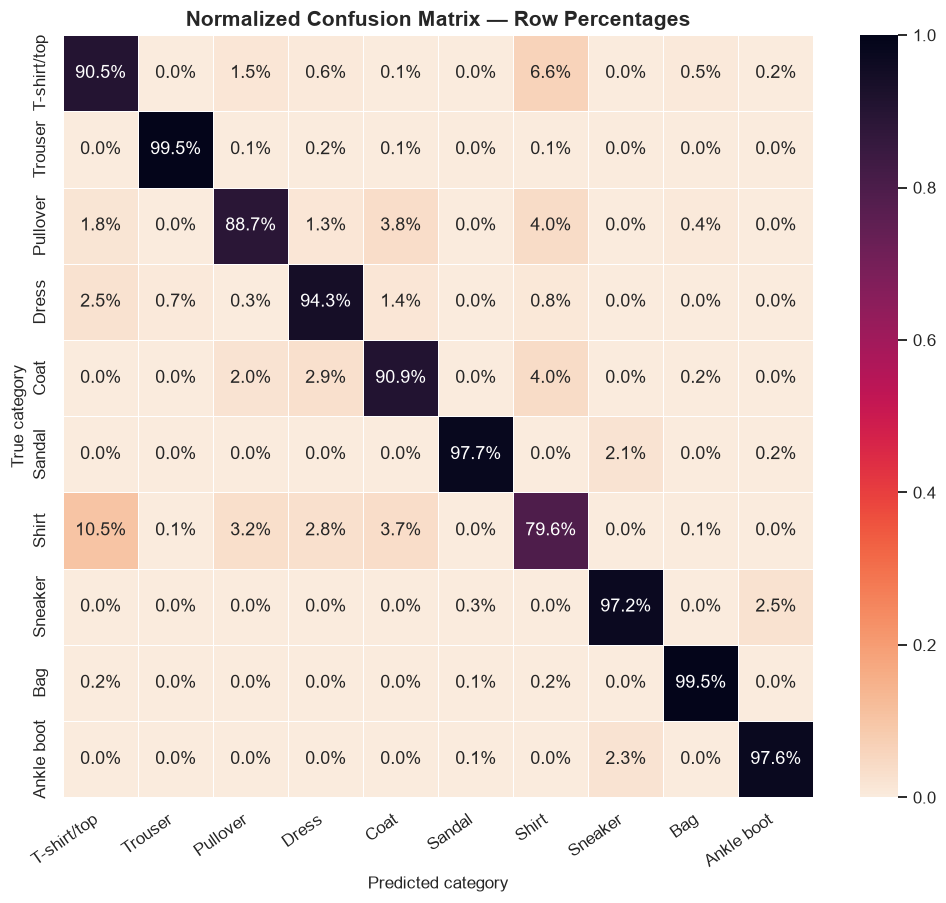

In [70]:
# 70 — Row-normalized confusion matrix
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(normalized_cm, annot=True, fmt=".1%", cmap="rocket_r", vmin=0, vmax=1,
            linewidths=0.5, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(title="Normalized Confusion Matrix — Row Percentages", xlabel="Predicted category", ylabel="True category")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
save_and_show(fig, "15_normalized_confusion_matrix.png")

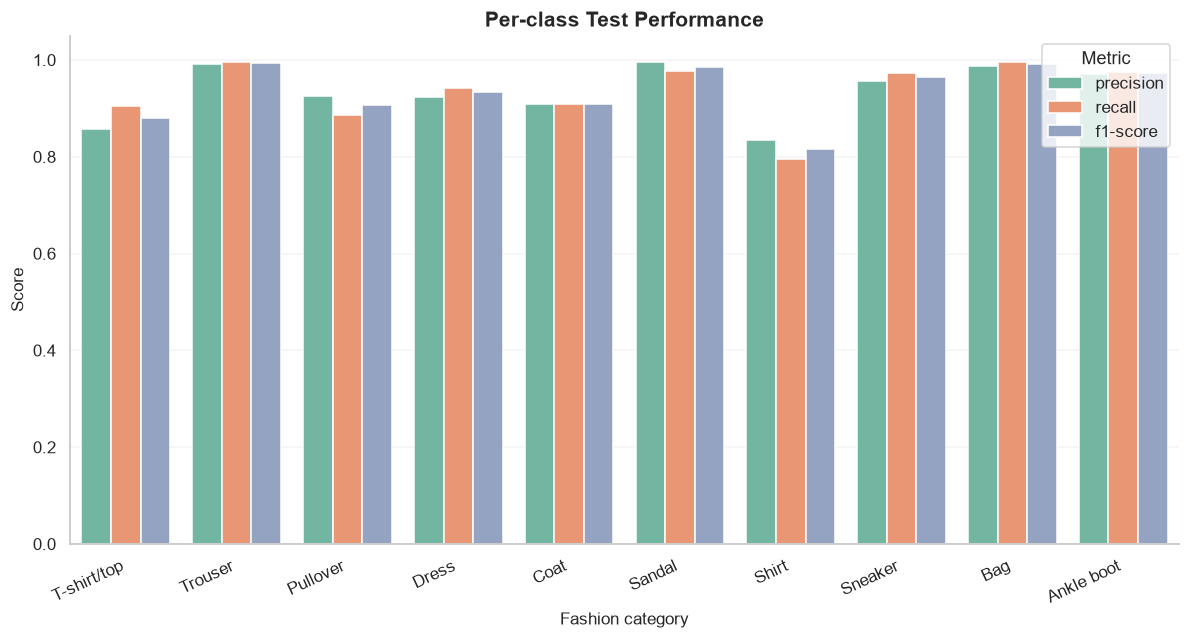

In [71]:
# 71 — Class-wise precision, recall, and F1 visualization
metrics_long = report_df.reset_index(names="Class").melt(
    id_vars="Class", value_vars=["precision", "recall", "f1-score"],
    var_name="Metric", value_name="Score"
)
fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=metrics_long, x="Class", y="Score", hue="Metric", palette="Set2", ax=ax)
ax.set(title="Per-class Test Performance", xlabel="Fashion category", ylabel="Score", ylim=(0, 1.05))
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
save_and_show(fig, "16_classification_metrics_by_class.png")

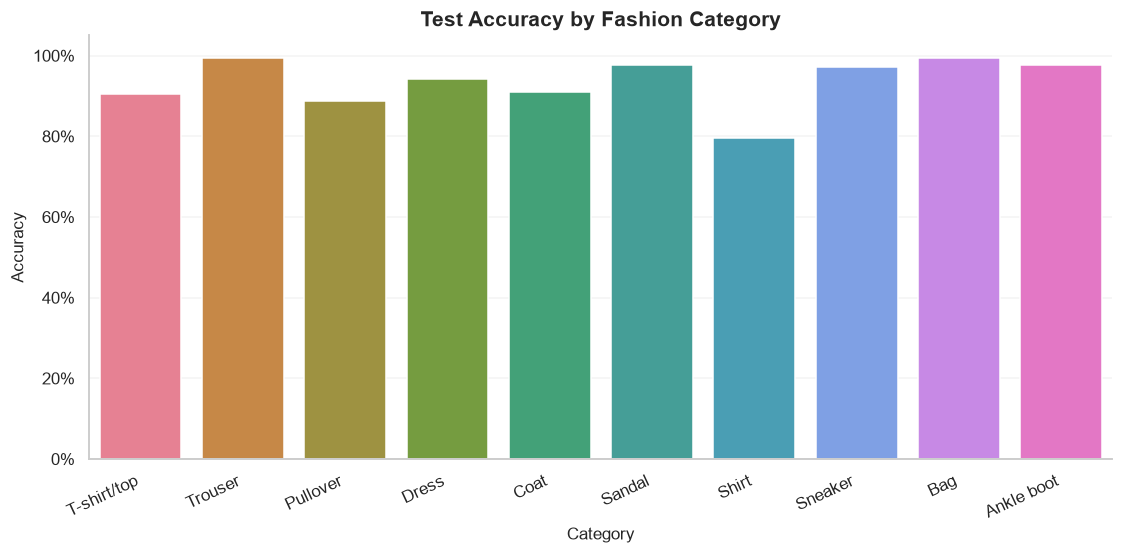

In [72]:
# 72 — Per-class accuracy
class_accuracy = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)
class_accuracy_df = pd.DataFrame({"Class": CLASS_NAMES, "Accuracy": class_accuracy})
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=class_accuracy_df, x="Class", y="Accuracy", hue="Class", palette=CLASS_COLORS, legend=False, ax=ax)
ax.set(title="Test Accuracy by Fashion Category", xlabel="Category", ylabel="Accuracy", ylim=(0, 1.05))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
save_and_show(fig, "17_per_class_accuracy.png")

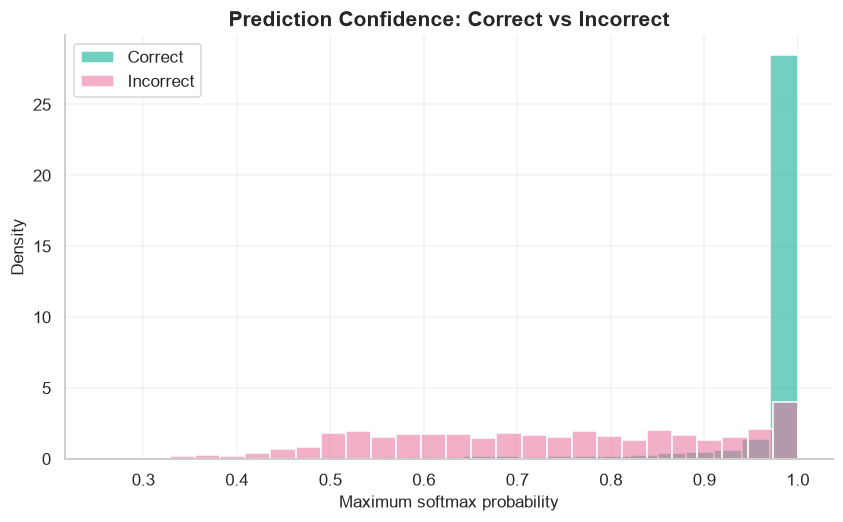

In [73]:
# 73 — Confidence distribution for correct and incorrect predictions
confidence = test_results["probabilities"].max(axis=1)
correct_mask = test_results["y_true"] == test_results["y_pred"]
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(confidence[correct_mask], bins=25, color="#00A88F", label="Correct", stat="density", alpha=0.55, ax=ax)
sns.histplot(confidence[~correct_mask], bins=25, color="#E76F9A", label="Incorrect", stat="density", alpha=0.55, ax=ax)
ax.set(title="Prediction Confidence: Correct vs Incorrect", xlabel="Maximum softmax probability", ylabel="Density")
ax.legend()
save_and_show(fig, "18_prediction_confidence.png")

In [74]:
# 74 — Build a table of misclassified examples
misclassified_indices = np.flatnonzero(~correct_mask)
misclassified_df = pd.DataFrame({
    "test_index": misclassified_indices,
    "true_label": test_results["y_true"][misclassified_indices],
    "true_class": [CLASS_NAMES[i] for i in test_results["y_true"][misclassified_indices]],
    "predicted_label": test_results["y_pred"][misclassified_indices],
    "predicted_class": [CLASS_NAMES[i] for i in test_results["y_pred"][misclassified_indices]],
    "confidence": confidence[misclassified_indices]
}).sort_values("confidence", ascending=False)
print(f"Misclassified examples: {len(misclassified_df):,}")

Misclassified examples: 645


In [75]:
# 75 — Inspect the most frequent error pairs
error_pairs = (
    misclassified_df.groupby(["true_class", "predicted_class"]).size()
    .sort_values(ascending=False).head(12).rename("Count").reset_index()
)
display(error_pairs)

,true_class,predicted_class,Count
0,Shirt,T-shirt/top,105
1,T-shirt/top,Shirt,66
2,Coat,Shirt,40
3,Pullover,Shirt,40
4,Pullover,Coat,38
5,Shirt,Coat,37
6,Shirt,Pullover,32
7,Coat,Dress,29
8,Shirt,Dress,28
9,Dress,T-shirt/top,25


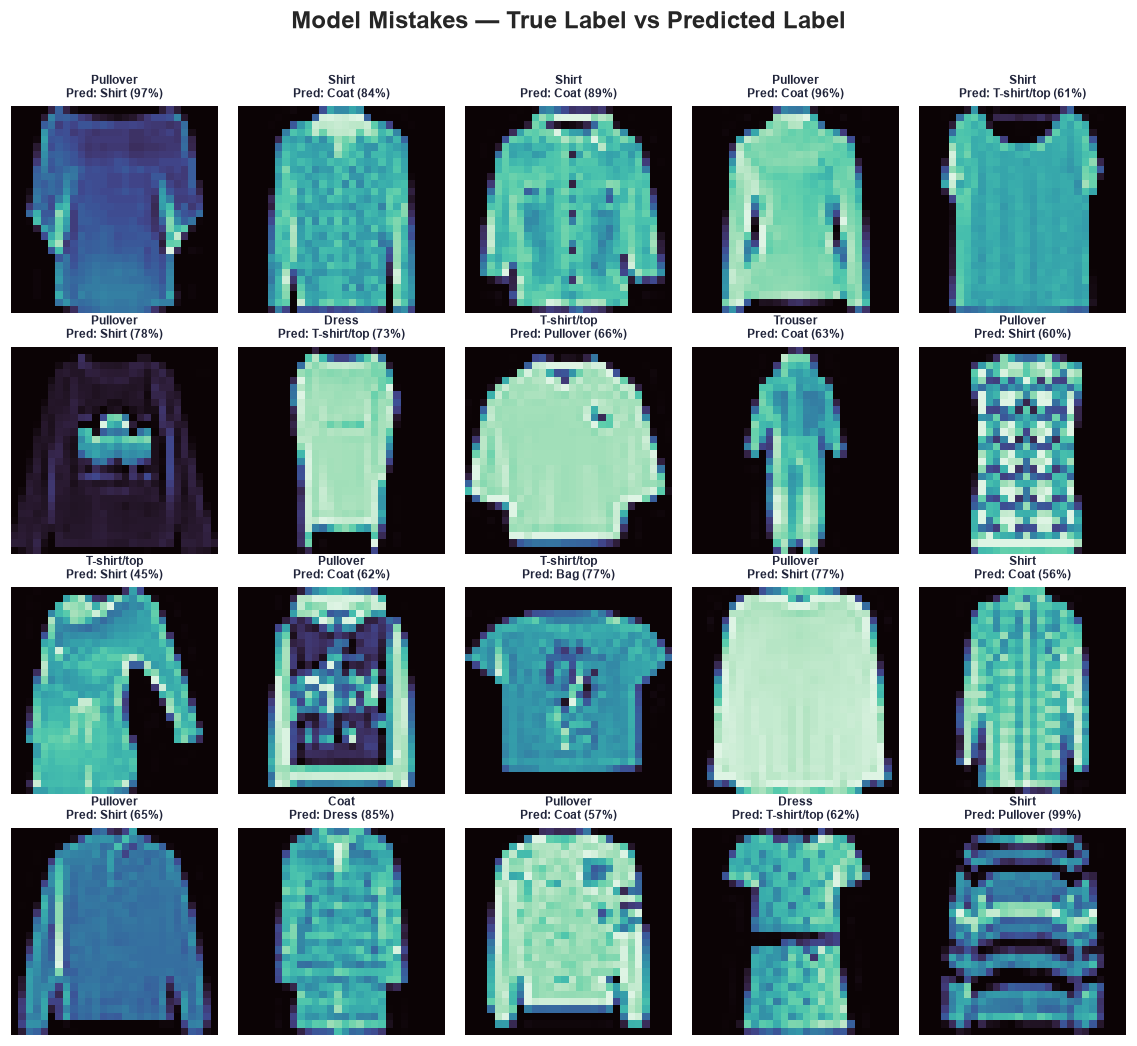

In [76]:
# 76 — Visual review of incorrect predictions
if len(misclassified_indices) > 0:
    error_sample = misclassified_indices[:20]
    show_image_grid(
        X_test_raw[error_sample], test_results["y_true"][error_sample],
        predictions=test_results["y_pred"][error_sample],
        confidences=confidence[error_sample], nrows=4, ncols=5,
        title="Model Mistakes — True Label vs Predicted Label",
        filename="19_misclassified_examples.png"
    )
else:
    print("No test errors were found in this run.")

In [77]:
# 77 — High-confidence mistakes deserve special attention
high_confidence_errors = misclassified_df[misclassified_df["confidence"] >= 0.80].head(15)
display(high_confidence_errors)

,test_index,true_label,true_class,predicted_label,predicted_class,confidence
116,1745,5,Sandal,7,Sneaker,0.999964
146,2128,0,T-shirt/top,3,Dress,0.999933
481,7402,5,Sandal,7,Sneaker,0.999921
461,7014,5,Sandal,7,Sneaker,0.999422
625,9634,7,Sneaker,9,Ankle boot,0.999376
602,9224,6,Shirt,4,Coat,0.999298
298,4508,9,Ankle boot,7,Sneaker,0.999274
24,356,6,Shirt,0,T-shirt/top,0.999211
454,6862,9,Ankle boot,5,Sandal,0.999128
384,5927,6,Shirt,3,Dress,0.998834


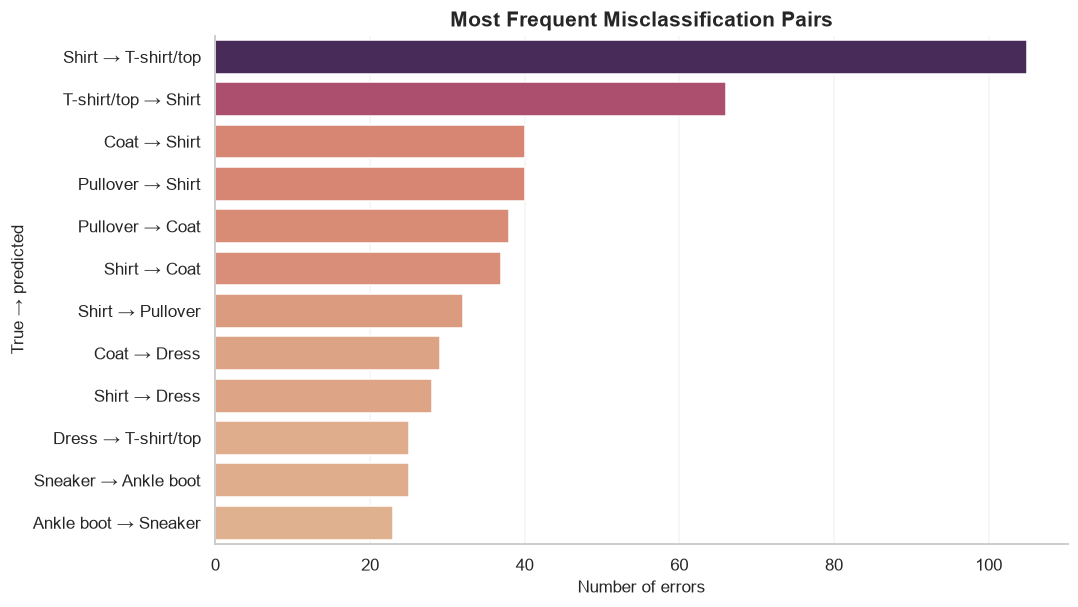

In [78]:
# 78 — Most common confusion pairs visualization
if not error_pairs.empty:
    error_pairs["Pair"] = error_pairs["true_class"] + " → " + error_pairs["predicted_class"]
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=error_pairs, y="Pair", x="Count", hue="Count", palette="flare", legend=False, ax=ax)
    ax.set(title="Most Frequent Misclassification Pairs", xlabel="Number of errors", ylabel="True → predicted")
    save_and_show(fig, "20_top_confusion_pairs.png")

## 7. Prediction utilities and qualitative review

In [79]:
# 79 — Reusable single-image inference function
@torch.no_grad()
def predict_single(image_array):
    model.eval()
    tensor = torch.as_tensor(image_array, dtype=torch.float32).reshape(1, 1, 28, 28)
    tensor = tensor.to(DEVICE)
    probabilities = torch.softmax(model(tensor), dim=1).squeeze(0).cpu().numpy()
    predicted_id = int(probabilities.argmax())
    return {
        "class_id": predicted_id, "class_name": CLASS_NAMES[predicted_id],
        "confidence": float(probabilities[predicted_id]), "probabilities": probabilities
    }

In [80]:
# 80 — Inspect one model prediction
example_index = int(rng.integers(0, len(X_test)))
example_prediction = predict_single(X_test[example_index])
print("True category:", CLASS_NAMES[int(y_test[example_index])])
print("Predicted category:", example_prediction["class_name"])
print(f"Confidence: {example_prediction['confidence']:.2%}")

True category: Bag
Predicted category: Bag
Confidence: 100.00%


In [81]:
# 81 — Prepare a compact test prediction sample
prediction_sample_indices = rng.choice(len(X_test), size=25, replace=False)
prediction_sample_images = X_test_raw[prediction_sample_indices]
prediction_sample_true = test_results["y_true"][prediction_sample_indices]
prediction_sample_pred = test_results["y_pred"][prediction_sample_indices]
prediction_sample_conf = confidence[prediction_sample_indices]

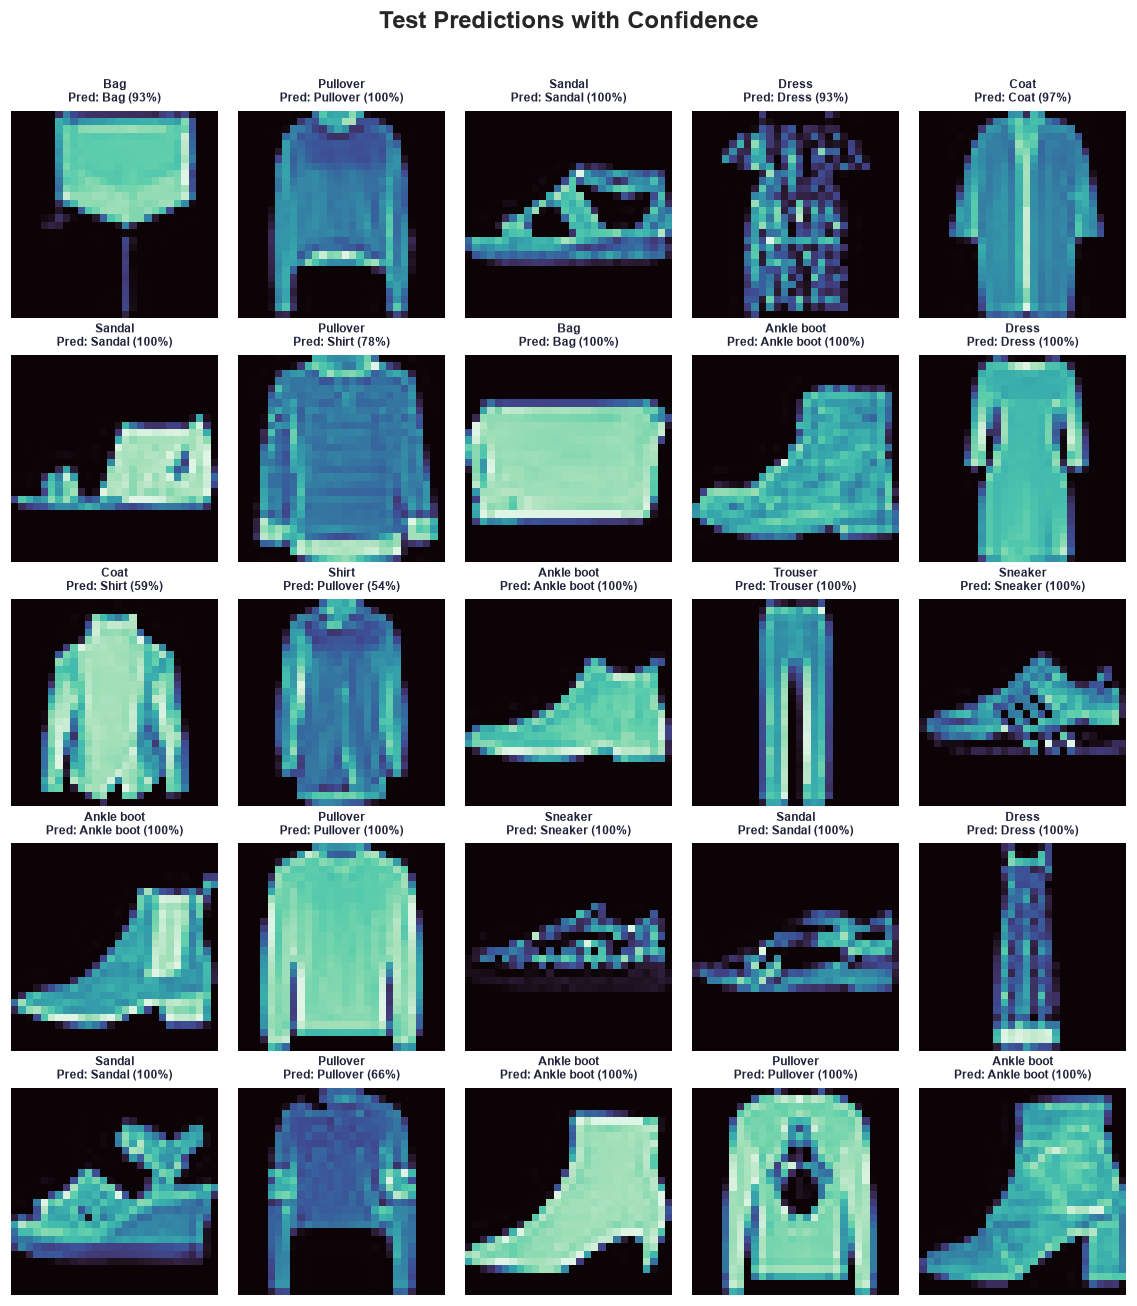

In [82]:
# 82 — Visual prediction gallery
show_image_grid(
    prediction_sample_images, prediction_sample_true,
    predictions=prediction_sample_pred, confidences=prediction_sample_conf,
    nrows=5, ncols=5, title="Test Predictions with Confidence",
    filename="21_test_prediction_gallery.png"
)

## 8. Export reproducible experiment artifacts

In [83]:
# 83 — Export per-image test predictions
predictions_export = pd.DataFrame({
    "true_label": test_results["y_true"],
    "true_class": [CLASS_NAMES[i] for i in test_results["y_true"]],
    "predicted_label": test_results["y_pred"],
    "predicted_class": [CLASS_NAMES[i] for i in test_results["y_pred"]],
    "confidence": confidence
})
for class_id, class_name in enumerate(CLASS_NAMES):
    predictions_export[f"probability_{class_id}"] = test_results["probabilities"][:, class_id]
predictions_export.to_csv(ARTIFACTS_DIR / "test_predictions.csv", index=False)

In [84]:
# 84 — Export class-wise evaluation report
report_df.to_csv(ARTIFACTS_DIR / "classification_report.csv", index=True)

In [85]:
# 85 — Export learning history
history_df.to_csv(ARTIFACTS_DIR / "training_history.csv", index=False)

In [86]:
# 86 — Export headline metrics as JSON
with open(ARTIFACTS_DIR / "evaluation_metrics.json", "w", encoding="utf-8") as file:
    json.dump(headline_metrics, file, indent=4)

In [87]:
# 87 — Save a portable final model checkpoint
final_checkpoint = {
    "model_state_dict": model.state_dict(),
    "model_config": MODEL_CONFIG,
    "class_names": CLASS_NAMES,
    "test_accuracy": float(test_results["accuracy"])
}
torch.save(final_checkpoint, ARTIFACTS_DIR / "fashion_cnn_final.pt")

In [88]:
# 88 — Export raw and normalized confusion matrices
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(ARTIFACTS_DIR / "confusion_matrix.csv")
pd.DataFrame(normalized_cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(ARTIFACTS_DIR / "normalized_confusion_matrix.csv")

In [89]:
# 89 — Export the label mapping
with open(ARTIFACTS_DIR / "class_mapping.json", "w", encoding="utf-8") as file:
    json.dump({str(i): name for i, name in enumerate(CLASS_NAMES)}, file, indent=4)

In [90]:
# 90 — Save experiment metadata for reproducibility
run_metadata = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "device_type": DEVICE.type,
    "gpu_available": bool(USE_CUDA),
    "gpu_name": torch.cuda.get_device_name(0) if USE_CUDA else None,
    "train_rows": int(len(train_df)), "validation_rows": int(len(val_df)) if "val_df" in globals() else int(len(X_val)),
    "test_rows": int(len(test_df)),
    "seed": SEED, "model_config": MODEL_CONFIG,
    "headline_metrics": headline_metrics
}
with open(ARTIFACTS_DIR / "run_metadata.json", "w", encoding="utf-8") as file:
    json.dump(run_metadata, file, indent=4)

## 9. Model interpretability and robustness checks

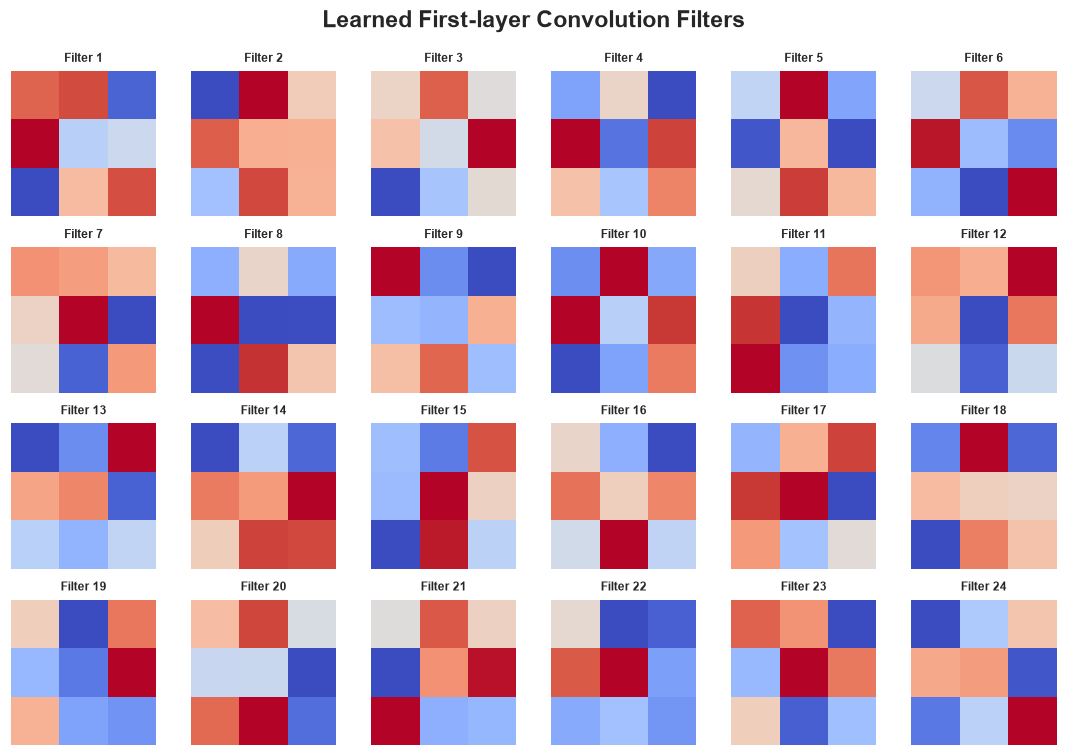

In [91]:
# 91 — Visualize learned filters from the first convolution layer
first_layer_weights = model.block1.conv1.weight.detach().cpu().numpy()
filter_count = min(24, first_layer_weights.shape[0])
fig, axes = plt.subplots(4, 6, figsize=(10, 7))
for idx, ax in enumerate(axes.flat):
    ax.axis("off")
    if idx < filter_count:
        ax.imshow(first_layer_weights[idx, 0], cmap="coolwarm")
        ax.set_title(f"Filter {idx + 1}", fontsize=8)
fig.suptitle("Learned First-layer Convolution Filters", fontsize=15, fontweight="bold")
fig.tight_layout()
save_and_show(fig, "22_first_layer_filters.png")

In [92]:
# 92 — Capture intermediate feature maps with a forward hook
activation_cache = {}
def capture_block1(module, inputs, output):
    activation_cache["block1"] = output.detach().cpu()
feature_hook = model.block1.register_forward_hook(capture_block1)
with torch.no_grad():
    _ = model(torch.from_numpy(X_test[:1]).to(DEVICE))
feature_hook.remove()
feature_maps = activation_cache["block1"][0].numpy()

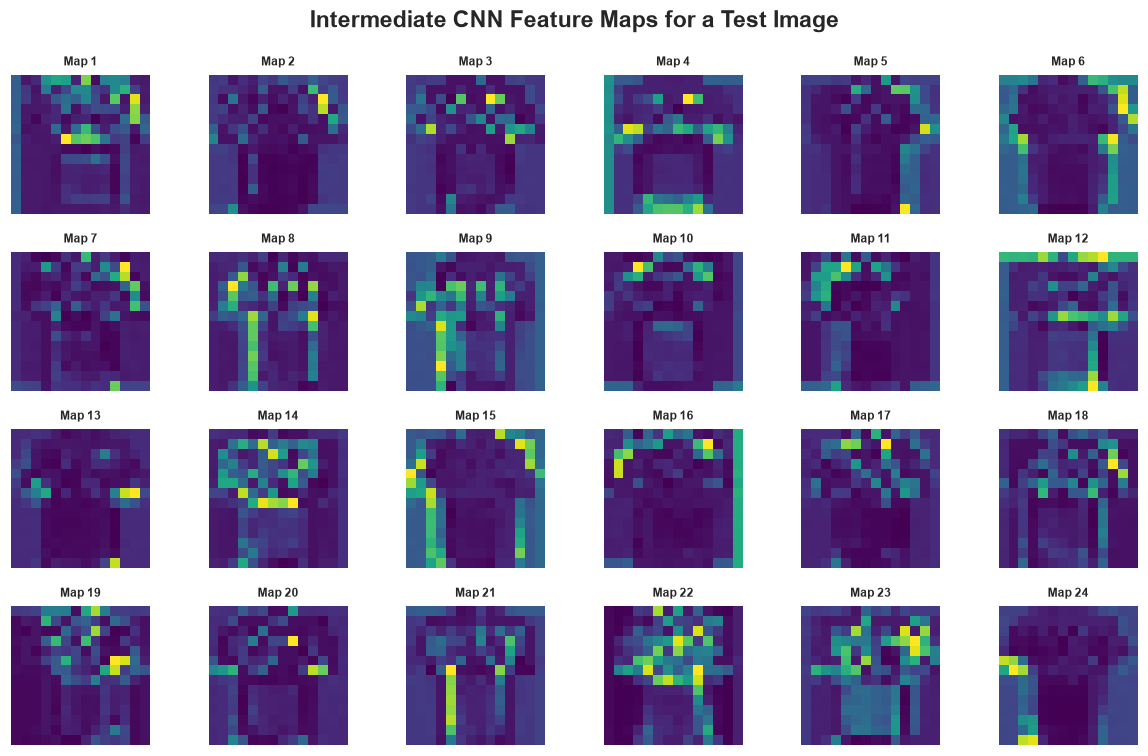

In [93]:
# 93 — Visualize learned feature-map activations
activation_count = min(24, feature_maps.shape[0])
fig, axes = plt.subplots(4, 6, figsize=(11, 7))
for idx, ax in enumerate(axes.flat):
    ax.axis("off")
    if idx < activation_count:
        ax.imshow(feature_maps[idx], cmap="viridis")
        ax.set_title(f"Map {idx + 1}", fontsize=8)
fig.suptitle("Intermediate CNN Feature Maps for a Test Image", fontsize=15, fontweight="bold")
fig.tight_layout()
save_and_show(fig, "23_intermediate_feature_maps.png")

In [94]:
# 94 — Lightweight single-image inference benchmark
benchmark_tensor = torch.from_numpy(X_test[:1]).to(DEVICE)
with torch.no_grad():
    for _ in range(10):
        _ = model(benchmark_tensor)
    if USE_CUDA:
        torch.cuda.synchronize()
    timing_start = time.perf_counter()
    repetitions = 100
    for _ in range(repetitions):
        _ = model(benchmark_tensor)
    if USE_CUDA:
        torch.cuda.synchronize()
inference_ms = (time.perf_counter() - timing_start) * 1000 / repetitions
print(f"Average single-image inference time: {inference_ms:.3f} ms")

Average single-image inference time: 2.238 ms


In [95]:
# 95 — Evaluate robustness to moderate Gaussian pixel noise
noise_rng = np.random.default_rng(SEED + 1)
robustness_count = min(5000, len(X_test))
noise_std = 0.15
noisy_subset = np.clip(
    X_test[:robustness_count] + noise_rng.normal(0, noise_std, X_test[:robustness_count].shape),
    0.0, 1.0
).astype(np.float32)
noisy_dataset = FashionDataset(noisy_subset, y_test[:robustness_count])
noisy_loader = DataLoader(noisy_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=PIN_MEMORY)
noisy_metrics = evaluate_model(model, noisy_loader, criterion, collect=False)
robustness_summary = pd.DataFrame({
    "Condition": ["Clean images", "Gaussian-noisy images"],
    "Accuracy": [test_results["accuracy"], noisy_metrics["accuracy"]]
})
display(robustness_summary)

,Condition,Accuracy
0,Clean images,0.9355
1,Gaussian-noisy images,0.4806


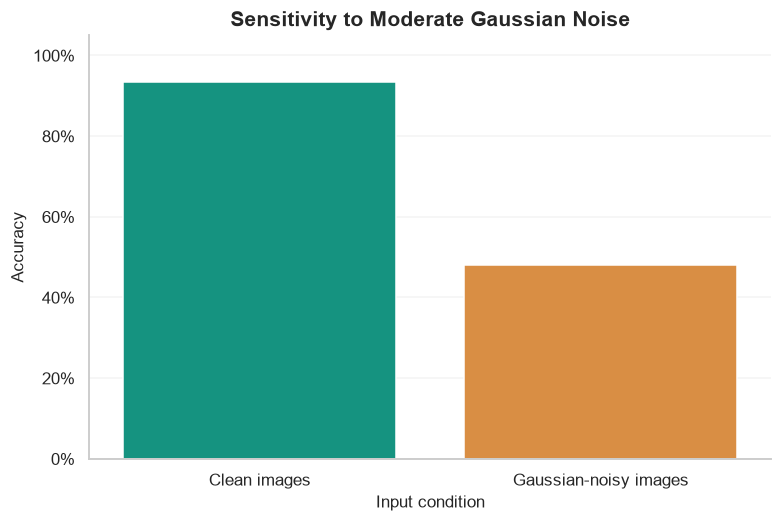

In [96]:
# 96 — Compare clean and noisy test performance
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=robustness_summary, x="Condition", y="Accuracy", hue="Condition", palette=["#00A88F", "#F28E2B"], legend=False, ax=ax)
ax.set(title="Sensitivity to Moderate Gaussian Noise", xlabel="Input condition", ylabel="Accuracy", ylim=(0, 1.05))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
save_and_show(fig, "24_noise_robustness.png")
robustness_summary.to_csv(ARTIFACTS_DIR / "noise_robustness.csv", index=False)

In [97]:
# 97 — Build a simple confidence-calibration table
calibration_confidence = confidence
calibration_correct = correct_mask.astype(np.float32)
calibration_bins = np.linspace(0.0, 1.0, 11)
bin_ids = np.digitize(calibration_confidence, calibration_bins[1:-1], right=False)
calibration_rows = []
for bin_id in range(10):
    mask = bin_ids == bin_id
    if mask.any():
        calibration_rows.append({
            "bin_midpoint": (calibration_bins[bin_id] + calibration_bins[bin_id + 1]) / 2,
            "mean_confidence": float(calibration_confidence[mask].mean()),
            "observed_accuracy": float(calibration_correct[mask].mean()),
            "count": int(mask.sum())
        })
calibration_df = pd.DataFrame(calibration_rows)
display(calibration_df)

,bin_midpoint,mean_confidence,observed_accuracy,count
0,0.25,0.266160,1.000000,2
1,0.35,0.373330,0.312500,16
2,0.45,0.464212,0.371429,70
3,0.55,0.550316,0.504274,234
4,0.65,0.652616,0.573705,251
5,0.75,0.752541,0.612457,289
6,0.85,0.856153,0.748184,413
7,0.95,0.993366,0.982693,8725


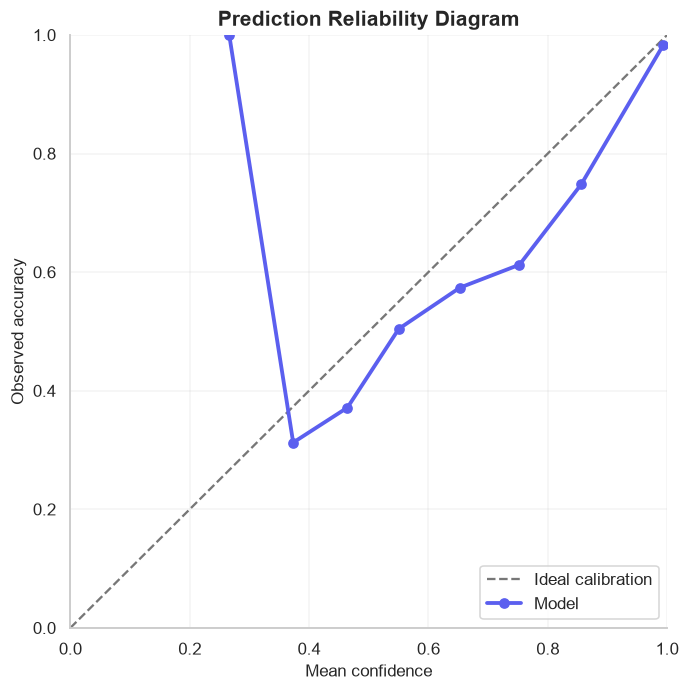

In [98]:
# 98 — Reliability diagram
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Ideal calibration")
if not calibration_df.empty:
    ax.plot(calibration_df["mean_confidence"], calibration_df["observed_accuracy"],
            marker="o", linewidth=2.5, color="#5B5FEF", label="Model")
ax.set(title="Prediction Reliability Diagram", xlabel="Mean confidence", ylabel="Observed accuracy", xlim=(0, 1), ylim=(0, 1))
ax.legend()
save_and_show(fig, "25_reliability_diagram.png")
calibration_df.to_csv(ARTIFACTS_DIR / "calibration_summary.csv", index=False)

## 10. Final experiment dashboard and completion checks

In [99]:
# 99 — Verify that the expected deliverables were generated
image_files = [p for p in IMAGES_DIR.iterdir() if p.is_file()]
artifact_files = [p for p in ARTIFACTS_DIR.iterdir() if p.is_file()]
completion_summary = pd.DataFrame({
    "Output group": ["Visualizations", "Model and analysis artifacts"],
    "Files created": [len(image_files), len(artifact_files)]
})
display(completion_summary)
assert len(image_files) >= 15 and len(artifact_files) >= 8

,Output group,Files created
0,Visualizations,128
1,Model and analysis artifacts,75


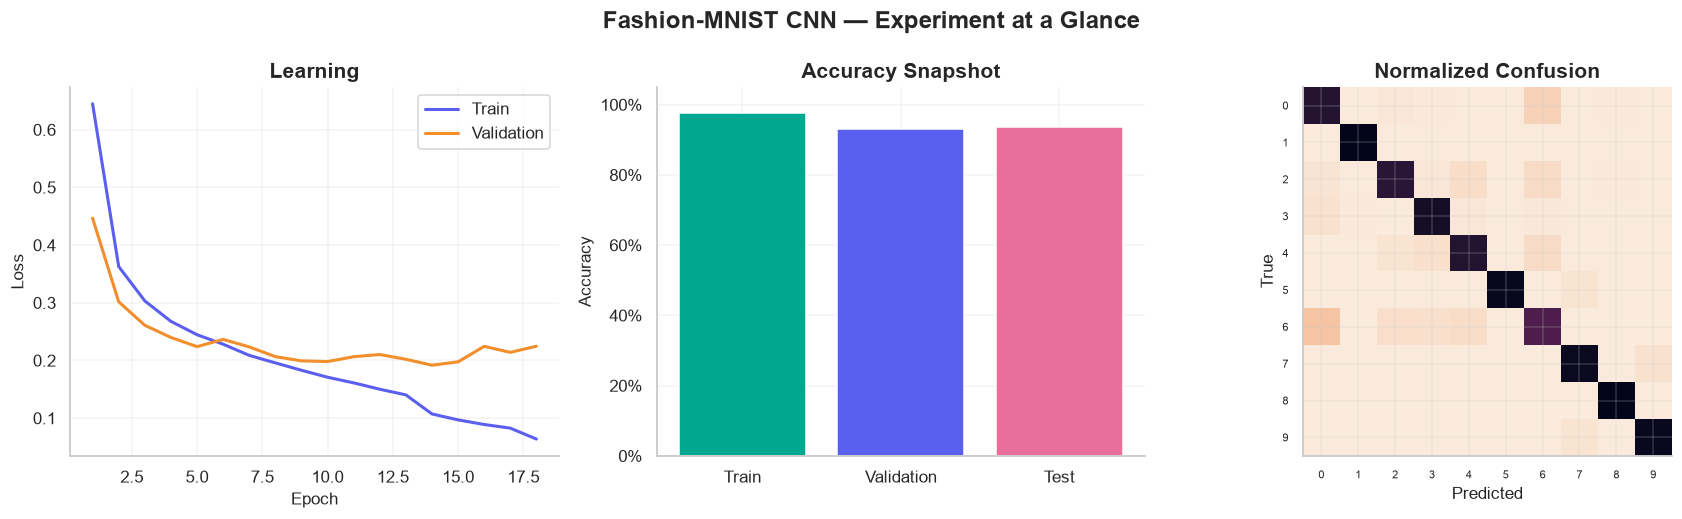

Final test accuracy: 93.55% | Visualizations: 128 | Artifact files: 75


In [100]:
# 100 — Executive experiment dashboard
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train", color="#5B5FEF", linewidth=2)
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation", color="#F28E2B", linewidth=2)
axes[0].set(title="Learning", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
metric_names = ["Train", "Validation", "Test"]
metric_values = [train_final_metrics["accuracy"], val_final_metrics["accuracy"], test_results["accuracy"]]
axes[1].bar(metric_names, metric_values, color=["#00A88F", "#5B5FEF", "#E76F9A"])
axes[1].set(title="Accuracy Snapshot", ylabel="Accuracy", ylim=(0, 1.05))
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
axes[2].imshow(normalized_cm, cmap="rocket_r", vmin=0, vmax=1)
axes[2].set(title="Normalized Confusion", xlabel="Predicted", ylabel="True")
axes[2].set_xticks(range(10), range(10), fontsize=7)
axes[2].set_yticks(range(10), range(10), fontsize=7)
fig.suptitle("Fashion-MNIST CNN — Experiment at a Glance", fontsize=16, fontweight="bold")
fig.tight_layout()
save_and_show(fig, "26_final_experiment_dashboard.png")
print(f"Final test accuracy: {test_results['accuracy']:.2%} | Visualizations: {len(image_files)} | Artifact files: {len(artifact_files)}")